In [ ]:
import warnings
warnings.filterwarnings("ignore")

#!pip install pyyaml

In [ ]:
# ── COLAB: Mount Google Drive so your 'dataset' folder is accessible
from google.colab import drive
drive.mount('/content/drive')

# After mounting, set DATASET_PATH to wherever your dataset folder lives in Drive.
# Example: if your Drive has  MyDrive/dataset/  then use:
DATASET_PATH = '/content/drive/MyDrive/dataset'

Mounted at /content/drive


In [ ]:
# ── FIX 1: All old sub-module imports (keras.layers.core, .convolutional, etc.)
# ──        are now flat under keras.layers / tensorflow.keras
# ── FIX 2: Scale is a custom layer from the old repo — defined inline below
# ── FIX 3: SGD 'lr' kwarg renamed to 'learning_rate'
# ── FIX 4: keras.preprocessing moved to tensorflow.keras.preprocessing

import tensorflow as tf
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import (
    Input, ZeroPadding2D, Dense, Dropout, Activation,
    Conv2D, AveragePooling2D, GlobalAveragePooling2D,
    MaxPooling2D, BatchNormalization, Concatenate, Layer
)
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K
from sklearn.metrics import log_loss
import numpy as np
import os
import random
import cv2
import math
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split



# This is the exact same Scale layer from the original DenseNet-Keras repo by flyyufelix.
# It applies a learnable gamma (scale) and beta (shift) to the input — like a lightweight
# affine transform that works together with BatchNormalization.
class Scale(Layer):
    """Learnable scale (gamma) and shift (beta) layer.
    Replicates the custom Scale layer from the original DenseNet-Keras repo."""

    def __init__(self, axis=-1, **kwargs):
        self.axis = axis
        super(Scale, self).__init__(**kwargs)

    def build(self, input_shape):
        dim = int(input_shape[self.axis])
        shape = (dim,)
        self.gamma = self.add_weight(
            name='gamma', shape=shape,
            initializer='ones', trainable=True
        )
        self.beta = self.add_weight(
            name='beta', shape=shape,
            initializer='zeros', trainable=True
        )
        super(Scale, self).build(input_shape)

    def call(self, x):
        input_shape = K.int_shape(x)
        broadcast_shape = [1] * len(input_shape)
        broadcast_shape[self.axis] = input_shape[self.axis]
        return (
            K.reshape(self.gamma, broadcast_shape) * x +
            K.reshape(self.beta,  broadcast_shape)
        )

    def get_config(self):
        config = {'axis': self.axis}
        base   = super(Scale, self).get_config()
        return dict(list(base.items()) + list(config.items()))


def densenet121_model(img_rows, img_cols, color_type=1, nb_dense_block=4,
                      growth_rate=32, nb_filter=64, reduction=0.5,
                      dropout_rate=0.0, weight_decay=1e-4, num_classes=None):
    '''
    DenseNet 121 Model for Keras

    Model Schema is based on
    https://github.com/flyyufelix/DenseNet-Keras

    # Returns
        A Keras model instance.
    '''

    global concat_axis
    img_input = Input(shape=(img_rows, img_cols, color_type), name='data')
    concat_axis = 3

    # From architecture for ImageNet (Table 1 in the paper)
    nb_filter = 64
    nb_layers = [6, 12, 24, 16]  # For DenseNet-121

    # ── FIX 3: Convolution2D  →  Conv2D
    #           subsample=(2,2) →  strides=(2,2)
    #           bias=False      →  use_bias=False
    x = Conv2D(nb_filter, (7, 7), strides=(2, 2), name='conv1', use_bias=False)(img_input)
    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    x = MaxPooling2D((3, 3), strides=(2, 2))(x)

    # Add dense blocks
    for block_idx in range(nb_dense_block - 1):
        stage = block_idx + 2
        x, nb_filter = dense_block(
            x, stage, nb_layers[block_idx], nb_filter,
            growth_rate, dropout_rate=dropout_rate
        )
        x = transition_block(x, stage, nb_filter, dropout_rate=dropout_rate)
        nb_filter = int(nb_filter)

    final_stage = stage + 1
    x, nb_filter = dense_block(
        x, final_stage, nb_layers[-1], nb_filter,
        growth_rate, dropout_rate=dropout_rate
    )

    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)

    x_fc = GlobalAveragePooling2D()(x)
    x_fc = Dense(1000)(x_fc)
    x_fc = Activation('softmax')(x_fc)

    model = Model(img_input, x_fc)

    # Fine-tune head: replace with num_classes output
    x_newfc = GlobalAveragePooling2D()(x)
    x_newfc = Dense(num_classes)(x_newfc)
    x_newfc = Activation('softmax')(x_newfc)

    model = Model(img_input, x_newfc)

    # ── COLAB FIX: 'decay' kwarg is deprecated in Keras 3 (Colab TF 2.16+)
    #               Use ExponentialDecay schedule instead
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3, decay_steps=10000, decay_rate=0.9
    )
    sgd = SGD(learning_rate=lr_schedule, momentum=0.9, nesterov=True)
    model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])

    return model

In [ ]:
def conv_block(x, stage, branch, nb_filter, dropout_rate=None):
    '''Apply BatchNorm, Relu, bottleneck 1x1 Conv2D, 3x3 Conv2D, and optional dropout'''

    # 1x1 Convolution (Bottleneck layer)
    inter_channel = nb_filter * 4
    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    # ── FIX 3: Convolution2D(f,1,1,bias=False) → Conv2D(f,(1,1),use_bias=False)
    x = Conv2D(inter_channel, (1, 1), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    # 3x3 Convolution
    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    x = ZeroPadding2D((1, 1))(x)
    x = Conv2D(nb_filter, (3, 3), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    return x


def transition_block(x, stage, nb_filter, dropout_rate=None):
    '''Apply BatchNorm, 1x1 Convolution, AveragePooling, optional compression, dropout'''

    x = BatchNormalization(axis=concat_axis)(x)
    x = Scale(axis=concat_axis)(x)
    x = Activation('relu')(x)
    x = Conv2D(int(nb_filter), (1, 1), use_bias=False)(x)

    if dropout_rate:
        x = Dropout(dropout_rate)(x)

    x = AveragePooling2D((2, 2), strides=(2, 2))(x)

    return x


def dense_block(x, stage, nb_layers, nb_filter, growth_rate,
                dropout_rate=None, grow_nb_filters=True):
    '''Build a dense_block where the output of each conv_block is fed to subsequent ones
    # Arguments
        x: input tensor
        stage: index for dense block
        nb_layers: the number of layers of conv_block to append to the model.
        nb_filter: number of filters
        growth_rate: growth rate
        grow_nb_filters: flag to decide to allow number of filters to grow
    '''

    concat_feat = x

    for i in range(nb_layers):
        branch = i + 1
        x = conv_block(concat_feat, stage, branch, growth_rate, dropout_rate)

        # ── FIX 4: merge([...], mode='concat', concat_axis=...)  is REMOVED in Keras 2+
        #           Replace with the functional Concatenate layer
        concat_feat = Concatenate(axis=concat_axis)([concat_feat, x])

        if grow_nb_filters:
            nb_filter += growth_rate

    return concat_feat, nb_filter


# Implement your own load_data() module for your own dataset

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ── 3-WAY SPLIT: 65% Training | 20% Validation | 15% Testing
# ImageDataGenerator only supports a 2-way split natively, so we
# manually collect all file paths + labels, split them with
# train_test_split (twice), then feed each subset via flow_from_dataframe.

def load_data():
    filepaths, labels = [], []
    for class_name in sorted(os.listdir(DATASET_PATH)):
        class_dir = os.path.join(DATASET_PATH, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                filepaths.append(os.path.join(class_dir, fname))
                labels.append(class_name)

    df = pd.DataFrame({'filepath': filepaths, 'label': labels})

    # Step 1 — carve out 15% for testing (stratified so every class is represented)
    train_val_df, test_df = train_test_split(
        df, test_size=0.15, stratify=df['label'], random_state=42
    )

    # Step 2 — split the remaining 85% into 65% train and 20% val
    # 20 / 85 ≈ 0.2353 gives us the right proportions relative to the whole set
    val_fraction = 0.20 / 0.85
    train_df, val_df = train_test_split(
        train_val_df, test_size=val_fraction,
        stratify=train_val_df['label'], random_state=42
    )

    total = len(df)
    print(f'Total images  : {total}')
    print(f'Training      : {len(train_df)}  ({len(train_df)/total*100:.1f}%)')
    print(f'Validation    : {len(val_df)}  ({len(val_df)/total*100:.1f}%)')
    print(f'Test          : {len(test_df)}  ({len(test_df)/total*100:.1f}%)')

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        train_df, x_col='filepath', y_col='label',
        target_size=(224, 224), batch_size=16,
        class_mode='categorical', shuffle=True, seed=42
    )
    val_gen = datagen.flow_from_dataframe(
        val_df, x_col='filepath', y_col='label',
        target_size=(224, 224), batch_size=16,
        class_mode='categorical', shuffle=False
    )
    test_gen = datagen.flow_from_dataframe(
        test_df, x_col='filepath', y_col='label',
        target_size=(224, 224), batch_size=16,
        class_mode='categorical', shuffle=False
    )

    print('Classes:', train_gen.class_indices)
    return train_gen, val_gen, test_gen


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

if __name__ == '__main__':

    img_rows, img_cols = 224, 224
    channel     = 3
    num_classes = 4
    batch_size  = 16
    nb_epoch    = 2

    # ── Now returns THREE generators instead of two
    train_gen, val_gen, test_gen = load_data()

    model = densenet121_model(
        img_rows=img_rows, img_cols=img_cols,
        color_type=channel, num_classes=num_classes
    )
    model.summary()

    filepath   = 'bestmodel.keras'
    checkpoint = ModelCheckpoint(
        filepath, monitor='val_accuracy',
        verbose=1, save_best_only=True, mode='max'
    )

    history = model.fit(
        train_gen,
        epochs=nb_epoch,
        verbose=1,
        validation_data=val_gen,          # val set monitors training only
        callbacks=[checkpoint],
    )

    # ── Final evaluation uses the HELD-OUT TEST SET (never seen during training)
    predictions_test = model.predict(test_gen, verbose=1)
    score = log_loss(test_gen.classes, predictions_test)
    print(f'Test Log-Loss: {score:.4f}')


Total images  : 12491
Training      : 8118  (65.0%)
Validation    : 2499  (20.0%)
Test          : 1874  (15.0%)
Found 8118 validated image filenames belonging to 4 classes.
Found 2499 validated image filenames belonging to 4 classes.
Found 1874 validated image filenames belonging to 4 classes.
Classes: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 109, 109,  │      9,408 │ data[0][0]        │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 109, 109,  │        256 │ conv1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale (Scale)       │ (None, 109, 109,  │        128 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 109, 109,  │          0 │ scale[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 54, 54,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        256 │ max_pooling2d[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_1 (Scale)     │ (None, 54, 54,    │        128 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 54, 54,    │          0 │ scale_1[0][0]     │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 54, 54,    │      8,192 │ activation_1[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_2 (Scale)     │ (None, 54, 54,    │        256 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 54, 54,    │          0 │ scale_2[0][0]     │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 56, 56,    │          0 │ activation_2[0][… │
│ (ZeroPadding2D)     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 54, 54,    │     36,864 │ zero_padding2d[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 54, 54,    │          0 │ max_pooling2d[0]… │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        384 │ concatenate[0][0

 Total params: 12,268,548 (46.80 MB)

 Trainable params: 12,131,908 (46.28 MB)

 Non-trainable params: 136,640 (533.75 KB)

Epoch 1/2
508/508 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7251 - loss: 0.7182
Epoch 1: val_accuracy improved from None to 0.27771, saving model to bestmodel.keras

Epoch 1: finished saving model to bestmodel.keras
508/508 ━━━━━━━━━━━━━━━━━━━━ 4674s 9s/step - accuracy: 0.8022 - loss: 0.5312 - val_accuracy: 0.2777 - val_loss: 9.3585
Epoch 2/2
508/508 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.8779 - loss: 0.3297
Epoch 2: val_accuracy improved from 0.27771 to 0.30252, saving model to bestmodel.keras

Epoch 2: finished saving model to bestmodel.keras
508/508 ━━━━━━━━━━━━━━━━━━━━ 172s 339ms/step - accuracy: 0.8847 - loss: 0.3101 - val_accuracy: 0.3025 - val_loss: 13.8777
118/118 ━━━━━━━━━━━━━━━━━━━━ 825s 7s/step
Test Log-Loss: 6.9441


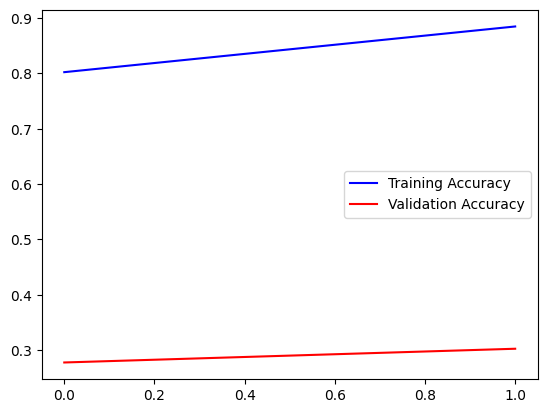

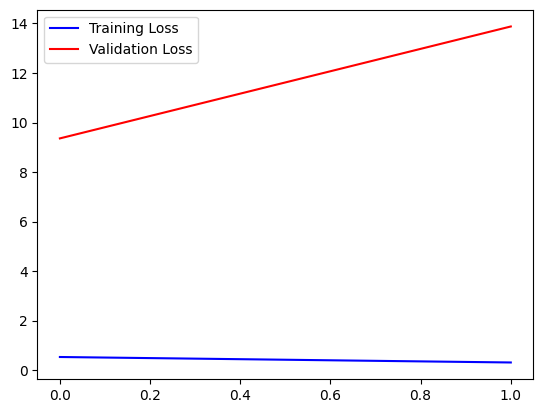

In [ ]:
# Evaluating Accuracy and Loss of the model
%matplotlib inline

# ── FIX 7: history keys 'acc' / 'val_acc'  →  'accuracy' / 'val_accuracy'
acc     = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss    = history.history['loss']
val_loss= history.history['val_loss']

epochs = range(len(acc))

import matplotlib.pyplot as plt

# Plot training and validation accuracy per epoch
plt.plot(epochs, acc,     'b', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r', label='Validation Accuracy')
plt.legend()
plt.figure()

# Plot training and validation loss per epoch
plt.plot(epochs, loss,     'b', label='Training Loss')
plt.plot(epochs, val_loss, 'r', label='Validation Loss')
plt.legend()
plt.show()

In [ ]:
# ── Use the TEST set for final prediction check (not the validation set)
xtest  = test_gen
ytest  = test_gen.classes        # integer class labels
ypred  = model.predict(test_gen, verbose=1)

import numpy as np
total         = 0
accurate      = 0
accurateindex = []
wrongindex    = []

for i in range(len(ypred)):
    if np.argmax(ypred[i]) == ytest[i]:
        accurate += 1
        accurateindex.append(i)
    else:
        wrongindex.append(i)
    total += 1

print('Total-test-data:', total,
      '\taccurately-predicted-data:', accurate,
      '\twrongly-predicted-data:', total - accurate)
print('Accuracy:', round(accurate / total * 100, 3), '%')


118/118 ━━━━━━━━━━━━━━━━━━━━ 24s 200ms/step
Total-test-data: 1874 	accurately-predicted-data: 572 	wrongly-predicted-data: 1302
Accuracy: 30.523 %


CLASSIFICATION REPORT (TEST SET)
               precision    recall  f1-score   support

      COVID19       0.00      0.00      0.00       461
       NORMAL       0.27      1.00      0.42       474
    PNEUMONIA       0.83      0.02      0.04       472
TURBERCULOSIS       0.85      0.19      0.31       467

     accuracy                           0.31      1874
    macro avg       0.49      0.30      0.19      1874
 weighted avg       0.49      0.31      0.19      1874

Overall Accuracy: 30.52%


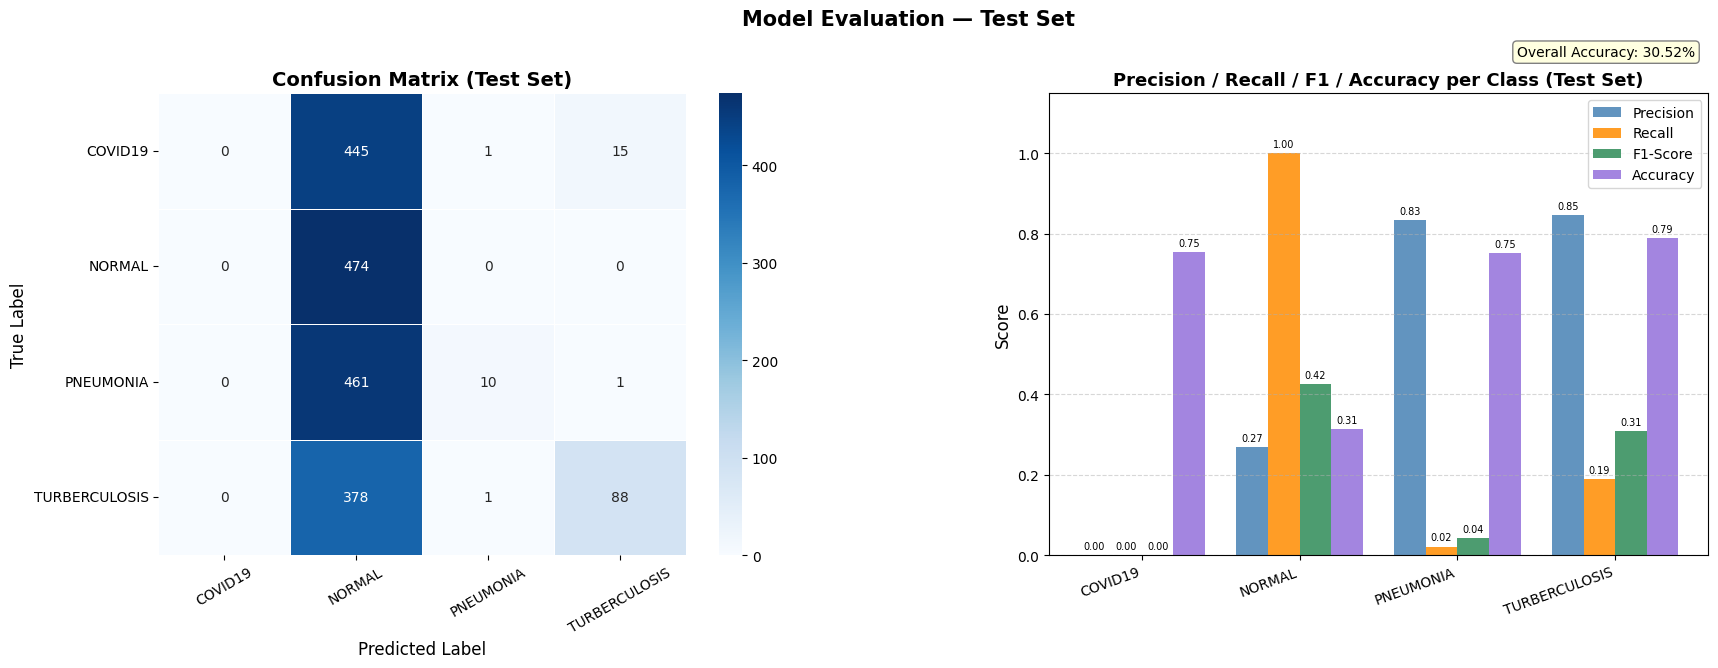

Figure saved as evaluation_metrics.png


In [ ]:
# ════════════════════════════════════════════════════════════════
# EVALUATION METRICS  —  Confusion Matrix · Precision · Recall · F1 · Accuracy
# ════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, accuracy_score
)

label = ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']

y_true = ytest
y_pred = np.argmax(ypred, axis=1)

# ── 1. Confusion Matrix ───────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)

# ── 2. Per-class metrics ──────────────────────────────────────────
precision = precision_score(y_true, y_pred, average=None, zero_division=0)
recall    = recall_score(y_true, y_pred, average=None, zero_division=0)
f1        = f1_score(y_true, y_pred, average=None, zero_division=0)

# ── Per-class accuracy from confusion matrix: (TP + TN) / total ──
total_samples = len(y_true)
per_class_accuracy = []
for i in range(len(label)):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp          # actual class i predicted as something else
    fp = cm[:, i].sum() - tp          # other classes predicted as i
    tn = total_samples - tp - fn - fp  # everything else
    per_class_accuracy.append((tp + tn) / total_samples)
per_class_accuracy = np.array(per_class_accuracy)

# ── Overall accuracy ──────────────────────────────────────────────
overall_acc = accuracy_score(y_true, y_pred)

print('=' * 60)
print('CLASSIFICATION REPORT (TEST SET)')
print('=' * 60)
print(classification_report(y_true, y_pred, target_names=label, zero_division=0))
print(f'Overall Accuracy: {overall_acc * 100:.2f}%')

# ── 3. Figures ────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 6))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.35)

# --- Left: Confusion Matrix heatmap ---
ax0 = fig.add_subplot(gs[0])
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=label, yticklabels=label,
    linewidths=0.5, ax=ax0
)
ax0.set_xlabel('Predicted Label', fontsize=12)
ax0.set_ylabel('True Label', fontsize=12)
ax0.set_title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
ax0.tick_params(axis='x', rotation=30)
ax0.tick_params(axis='y', rotation=0)

# --- Right: Grouped bar chart — Precision / Recall / F1 / Accuracy per class ---
ax1 = fig.add_subplot(gs[1])
x       = np.arange(len(label))
width   = 0.2
bars_p  = ax1.bar(x - 1.5*width, precision,           width, label='Precision', color='steelblue',  alpha=0.85)
bars_r  = ax1.bar(x - 0.5*width, recall,              width, label='Recall',    color='darkorange', alpha=0.85)
bars_f  = ax1.bar(x + 0.5*width, f1,                  width, label='F1-Score',  color='seagreen',   alpha=0.85)
bars_a  = ax1.bar(x + 1.5*width, per_class_accuracy,  width, label='Accuracy',  color='mediumpurple', alpha=0.85)

# Value labels on top of each bar
for bars in (bars_p, bars_r, bars_f, bars_a):
    for bar in bars:
        h = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2, h + 0.01,
            f'{h:.2f}', ha='center', va='bottom', fontsize=7
        )

ax1.set_xticks(x)
ax1.set_xticklabels(label, rotation=20, ha='right', fontsize=10)
ax1.set_ylim(0, 1.15)
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Precision / Recall / F1 / Accuracy per Class (Test Set)', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Add overall accuracy as a text annotation
ax1.text(0.98, 1.08, f'Overall Accuracy: {overall_acc*100:.2f}%',
         transform=ax1.transAxes, fontsize=10, ha='right',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray'))

plt.suptitle('Model Evaluation — Test Set', fontsize=15, fontweight='bold', y=1.02)
plt.savefig('evaluation_metrics.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figure saved as evaluation_metrics.png')


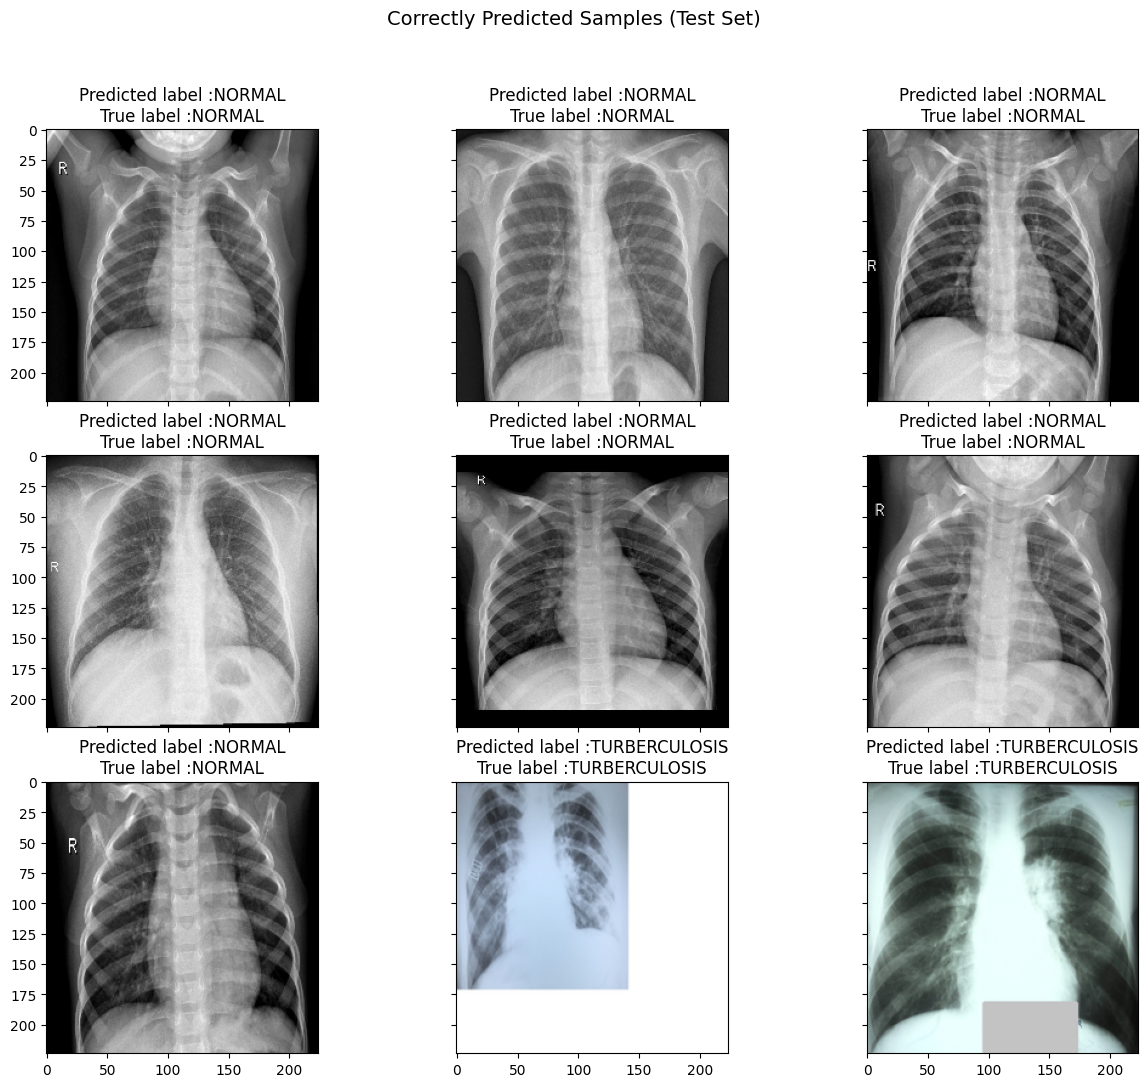

In [ ]:
label = ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']
imidx = random.sample(accurateindex, k=9)

nrows = 3
ncols = 3
fig, ax = plt.subplots(nrows, ncols, sharex=True, sharey=True, figsize=(15, 12))

# ── Now reads file paths from the TEST generator
test_filepaths = test_gen.filepaths

n = 0
for row in range(nrows):
    for col in range(ncols):
        img = cv2.imread(test_filepaths[imidx[n]])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        ax[row, col].imshow(img)
        ax[row, col].set_title(
            'Predicted label :{}\nTrue label :{}'.format(
                label[np.argmax(ypred[imidx[n]])],
                label[ytest[imidx[n]]]
            )
        )
        n += 1

plt.suptitle('Correctly Predicted Samples (Test Set)', fontsize=14)
plt.show()


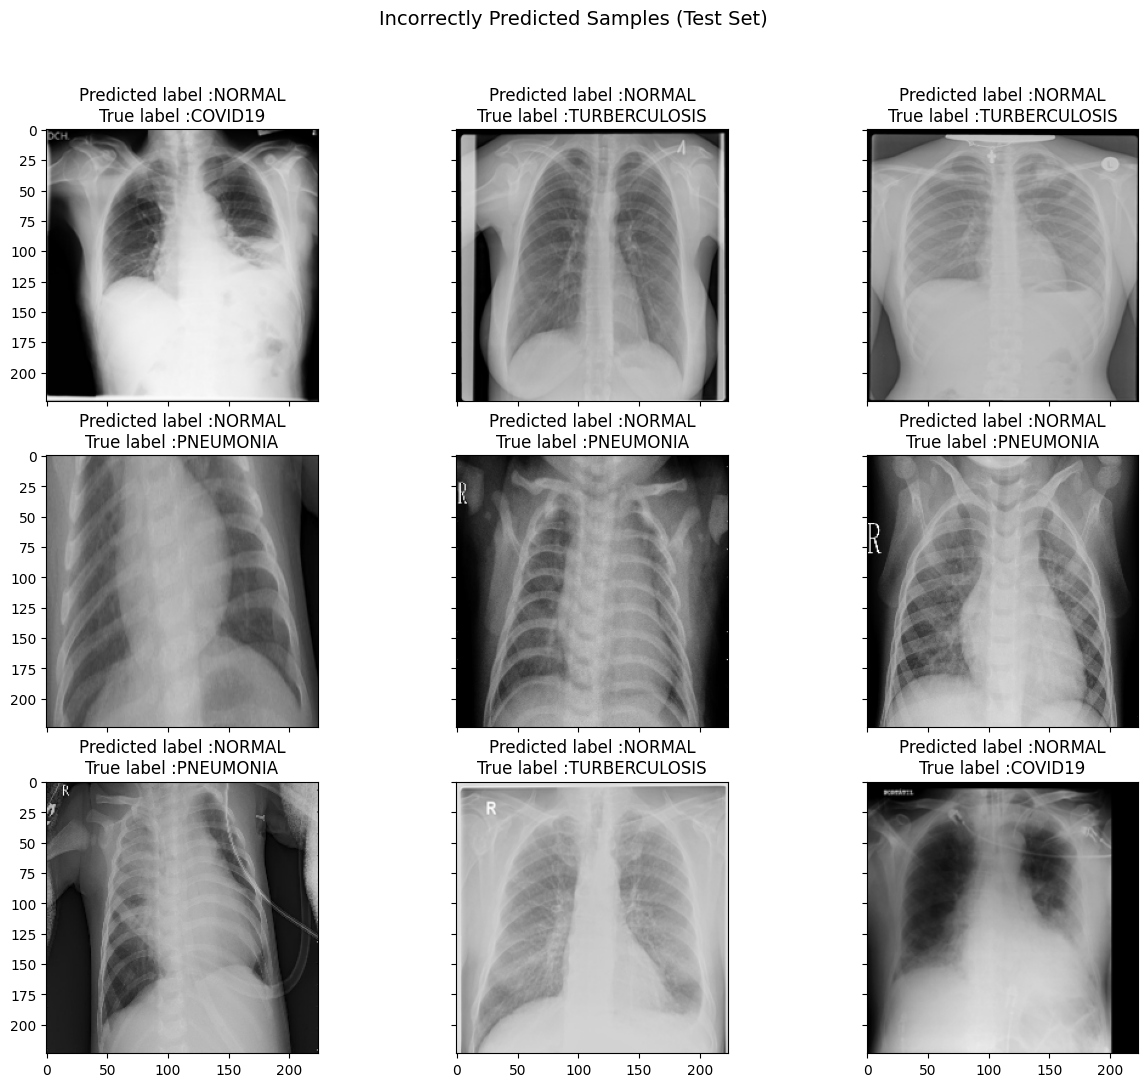

In [ ]:
label = ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']
imidx = random.sample(wrongindex, k=9)

nrows = 3
ncols = 3
fig, ax = plt.subplots(nrows, ncols, sharex=True, sharey=True, figsize=(15, 12))

# ── Now reads file paths from the TEST generator
test_filepaths = test_gen.filepaths

n = 0
for row in range(nrows):
    for col in range(ncols):
        img = cv2.imread(test_filepaths[imidx[n]])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        ax[row, col].imshow(img)
        ax[row, col].set_title(
            'Predicted label :{}\nTrue label :{}'.format(
                label[np.argmax(ypred[imidx[n]])],
                label[ytest[imidx[n]]]
            )
        )
        n += 1

plt.suptitle('Incorrectly Predicted Samples (Test Set)', fontsize=14)
plt.show()


In [ ]:
from tensorflow.keras.models import load_model

# The model weights (that are considered the best) are loaded into the model.
#model = load_model('bestmodel.keras')
#ypred = model.predict(xtest)